# V1DD soma coordinates

Reads the `v1dd_soma_spatial` `CellFeatureSet` written by `etl_v1dd_01_cave_dataset_celltypes.ipynb`
(feature definitions: `soma_voxel_{x,y,z}`, `soma_transformed_{x,y,z}`, `soma_volume`) and plots the
soma positions as scatterplots in four coordinate views:

- EM voxel coordinates, xy and xz projections
- streamline-transformed cortical coordinates (microns), xy and xz projections

For the xy projections, the y-axis is flipped so that y=0 (pia / top of the volume) is drawn at the
top of the plot.

In [1]:
from pathlib import Path

import pandas as pd
from deltalake import DeltaTable
from matplotlib import pyplot as plt

from connects_common_connectivity.io import get_settings

## Locate the `v1dd_soma_spatial` feature matrix

The CCM output root can either be the configured `output_root` (if this notebook is run right
after the ETL notebook in the same session) or a previously-built CCM dataset mounted as a data
asset (e.g. under `/data`). Try a few likely locations and use the first one that actually
contains the feature matrix.

In [2]:
PROJECT_ID = "v1dd"
FEATURE_SET_ID = "v1dd_soma_spatial"

candidate_roots = [
    Path(get_settings().output_root),
    #Path("/data/v1dd_1196_ccm"),
    Path("/scratch/v1dd_ccm_20260908"),
    #Path("/input/v1dd_1196_ccm"),
]

output_root = None
for candidate in candidate_roots:
    if (candidate / "cellfeatures" / FEATURE_SET_ID).exists():
        output_root = candidate
        break

if output_root is None:
    raise FileNotFoundError(
        f"Could not find a 'cellfeatures/{FEATURE_SET_ID}' table under any of: "
        f"{[str(c) for c in candidate_roots]}. Run etl_v1dd_01_cave_dataset_celltypes.ipynb first, "
        "or point one of the candidate_roots at the CCM output/data asset."
    )

print(f"Reading {FEATURE_SET_ID} feature matrix from: {output_root}")

Reading v1dd_soma_spatial feature matrix from: /scratch/v1dd_ccm_20260908


In [3]:
soma_spatial_dt = DeltaTable(output_root / "cellfeatures" / FEATURE_SET_ID)
soma_spatial_df = soma_spatial_dt.to_pandas()
soma_spatial_df = soma_spatial_df[soma_spatial_df["project_id"] == PROJECT_ID].reset_index(drop=True)

print(f"soma_spatial_df rows: {len(soma_spatial_df)}")
soma_spatial_df.head()

soma_spatial_df rows: 143448


,id,project_id,feature_set_id,soma_voxel_x,soma_voxel_y,soma_voxel_z,soma_transformed_x,soma_transformed_y,soma_transformed_z,soma_volume
0,864691132654552792,v1dd,v1dd_soma_spatial,624680.0,531094.0,283770.0,-248.956909,222.054901,16.022036,338.276611
1,864691132773514104,v1dd,v1dd_soma_spatial,894573.0,478559.0,163530.0,30.864260,135.367981,-105.097755,326.965393
2,864691132774106773,v1dd,v1dd_soma_spatial,1729859.0,674111.0,781200.0,804.489136,493.264465,468.374146,333.888641
3,864691132780109973,v1dd,v1dd_soma_spatial,1640231.0,677370.0,768015.0,714.854248,493.323730,454.734802,706.847046
4,864691132736203675,v1dd,v1dd_soma_spatial,1316562.0,974035.0,157590.0,348.218719,624.536255,-228.775909,200.069366


## Scatterplots: voxel vs. transformed coordinates

Four panels:

1. Voxel xy (`soma_voxel_x` vs `soma_voxel_y`)
2. Voxel xz (`soma_voxel_x` vs `soma_voxel_z`)
3. Transformed xy, in microns (`soma_transformed_x` vs `soma_transformed_y`)
4. Transformed xz, in microns (`soma_transformed_x` vs `soma_transformed_z`)

The two xy panels have their y-axis inverted so y=0 is at the top, matching image/cortical-depth
convention (pia at the top, increasing depth downward).

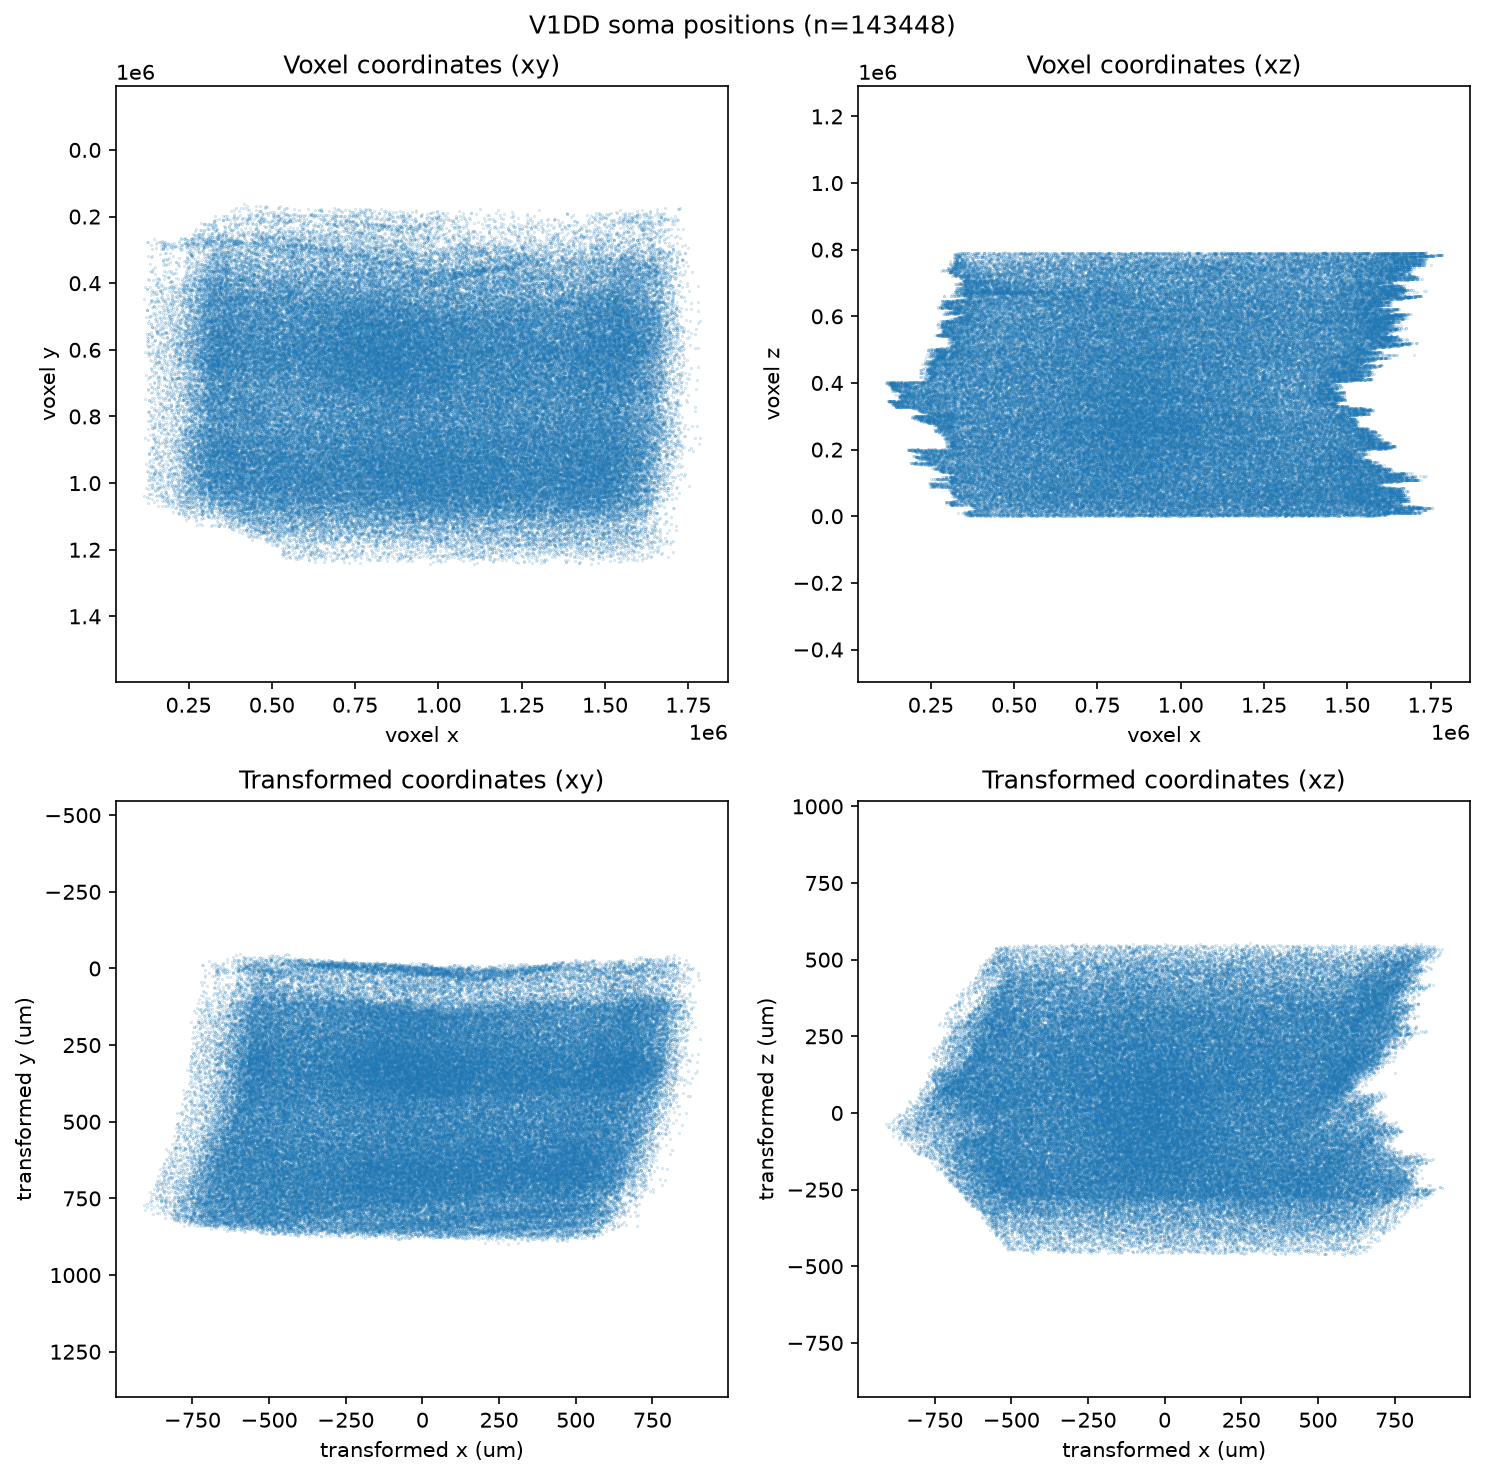

In [8]:
panels = [
    ("soma_voxel_x", "soma_voxel_y", "Voxel coordinates (xy)", "voxel x", "voxel y", True),
    ("soma_voxel_x", "soma_voxel_z", "Voxel coordinates (xz)", "voxel x", "voxel z", False),
    (
        "soma_transformed_x",
        "soma_transformed_y",
        "Transformed coordinates (xy)",
        "transformed x (um)",
        "transformed y (um)",
        True,
    ),
    (
        "soma_transformed_x",
        "soma_transformed_z",
        "Transformed coordinates (xz)",
        "transformed x (um)",
        "transformed z (um)",
        False,
    ),
]

fig, axs = plt.subplots(2, 2, figsize=(10, 10), dpi=150)

for ax, (xcol, ycol, title, xlabel, ylabel, flip_y) in zip(axs.flat, panels):
    ax.scatter(
        soma_spatial_df[xcol],
        soma_spatial_df[ycol],
        s=0.1,
        alpha=0.3,
        rasterized=True,
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_aspect("equal", adjustable="datalim")
    if flip_y:
        ax.invert_yaxis()

fig.suptitle(f"V1DD soma positions (n={len(soma_spatial_df)})")
fig.tight_layout()
plt.show()